In [48]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import time
import urllib.robotparser

In [49]:
SEED_URL = "https://quotes.toscrape.com/"
MAX_PAGES = 20
REQUEST_DELAY = 1
TIMEOUT = 10

print("Seed URL:", SEED_URL)

Seed URL: https://quotes.toscrape.com/


In [50]:
def normalize_url(url):
    parsed = urlparse(url)

    if parsed.scheme not in ["http", "https"]:
        return None

    return parsed.scheme + "://" + parsed.netloc + parsed.path.rstrip("/")

print(normalize_url(SEED_URL))

https://quotes.toscrape.com


In [51]:
import urllib.robotparser
from urllib.parse import urljoin

def allowed_by_robots(url):
    try:
        rp = urllib.robotparser.RobotFileParser()
        rp.set_url(urljoin(url, "/robots.txt"))
        rp.read()

        return rp.can_fetch("*", url)

    except Exception as e:
        print("Robots.txt check error:", e)
        return False

print("Robots.txt allowed:", allowed_by_robots(SEED_URL))

Robots.txt allowed: True


In [52]:
queue = deque([SEED_URL])
visited = set()
pages = []

while queue and len(visited) < MAX_PAGES:

    url = normalize_url(queue.popleft())

    if not url or url in visited:
        continue

    if not allowed_by_robots(url):
        continue

    try:
        response = requests.get(
            url,
            timeout=TIMEOUT,
            headers={"User-Agent": "GraphWebAnalyticsCrawler/1.0"}
        )

        if response.status_code != 200:
            continue

        visited.add(url)

        pages.append({
            "url": url,
            "status_code": response.status_code,
            "title": BeautifulSoup(response.text, "html.parser").title.string
                    if BeautifulSoup(response.text, "html.parser").title else "No Title"
        })

        soup = BeautifulSoup(response.text, "html.parser")

        for link in soup.find_all("a", href=True):
            next_url = normalize_url(urljoin(url, link["href"]))

            if next_url and next_url not in visited:
                queue.append(next_url)

        time.sleep(REQUEST_DELAY)

    except Exception as e:
        print("Error:", url, e)

print("Pages crawled:", len(pages))

Pages crawled: 20


In [53]:
links = []

for page in pages:
    try:
        response = requests.get(
            page["url"],
            timeout=TIMEOUT,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        soup = BeautifulSoup(response.text, "html.parser")

        for tag in soup.find_all("a", href=True):
            target = urljoin(page["url"], tag["href"])
            parsed = urlparse(target)

            # Keep only HTTP/HTTPS links
            if parsed.scheme in ["http", "https"]:
                target = normalize_url(target)

                if target:
                    links.append({
                        "source": page["url"],
                        "target": target
                    })

    except Exception as e:
        print("Error reading:", page["url"])

# Create DataFrame
links_df = pd.DataFrame(links)

print("Total links found:", len(links_df))

if len(links_df) > 0:
    display(links_df.head(10))
else:
    print("No links were found.")

Total links found: 536


,source,target
0,https://quotes.toscrape.com,https://quotes.toscrape.com
1,https://quotes.toscrape.com,https://quotes.toscrape.com/login
2,https://quotes.toscrape.com,https://quotes.toscrape.com/author/Albert-Eins...
3,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/change/page/1
4,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/deep-thoughts/...
5,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/thinking/page/1
6,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/world/page/1
7,https://quotes.toscrape.com,https://quotes.toscrape.com/author/J-K-Rowling
8,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/abilities/page/1
9,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/choices/page/1


In [54]:
pages_df = pd.DataFrame(pages)

print("Crawled Web Pages")
display(pages_df)

print("\nExtracted Links")
display(links_df.head(20))

Crawled Web Pages


,url,status_code,title
0,https://quotes.toscrape.com,200,Quotes to Scrape
1,https://quotes.toscrape.com/login,200,Quotes to Scrape
2,https://quotes.toscrape.com/author/Albert-Eins...,200,Quotes to Scrape
3,https://quotes.toscrape.com/tag/change/page/1,200,Quotes to Scrape
4,https://quotes.toscrape.com/tag/deep-thoughts/...,200,Quotes to Scrape
5,https://quotes.toscrape.com/tag/thinking/page/1,200,Quotes to Scrape
6,https://quotes.toscrape.com/tag/world/page/1,200,Quotes to Scrape
7,https://quotes.toscrape.com/author/J-K-Rowling,200,Quotes to Scrape
8,https://quotes.toscrape.com/tag/abilities/page/1,200,Quotes to Scrape
9,https://quotes.toscrape.com/tag/choices/page/1,200,Quotes to Scrape



Extracted Links


,source,target
0,https://quotes.toscrape.com,https://quotes.toscrape.com
1,https://quotes.toscrape.com,https://quotes.toscrape.com/login
2,https://quotes.toscrape.com,https://quotes.toscrape.com/author/Albert-Eins...
3,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/change/page/1
4,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/deep-thoughts/...
5,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/thinking/page/1
6,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/world/page/1
7,https://quotes.toscrape.com,https://quotes.toscrape.com/author/J-K-Rowling
8,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/abilities/page/1
9,https://quotes.toscrape.com,https://quotes.toscrape.com/tag/choices/page/1


In [55]:
G = nx.DiGraph()

for _, row in links_df.iterrows():
    G.add_edge(row["source"], row["target"])

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 119
Number of edges: 458


In [56]:
# BOX 9 - Graph Statistics

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

graph_stats = pd.DataFrame({
    "URL": list(G.nodes()),
    "Inlinks": [in_degree[node] for node in G.nodes()],
    "Outlinks": [out_degree[node] for node in G.nodes()]
})

print("Graph Statistics:")
display(graph_stats)

# Average degrees
if len(G.nodes()) > 0:
    avg_in_degree = sum(in_degree.values()) / len(G.nodes())
    avg_out_degree = sum(out_degree.values()) / len(G.nodes())

    print("Average In-degree:", round(avg_in_degree, 2))
    print("Average Out-degree:", round(avg_out_degree, 2))
else:
    print("Graph contains no nodes.")


Graph Statistics:


,URL,Inlinks,Outlinks
0,https://quotes.toscrape.com,20,49
1,https://quotes.toscrape.com/login,20,4
2,https://quotes.toscrape.com/author/Albert-Eins...,10,4
3,https://quotes.toscrape.com/tag/change/page/1,5,19
4,https://quotes.toscrape.com/tag/deep-thoughts/...,5,19
...,...,...,...
114,https://quotes.toscrape.com/tag/lies/page/1,1,0
115,https://quotes.toscrape.com/tag/lying/page/1,1,0
116,https://quotes.toscrape.com/tag/self-indulgenc...,1,0
117,https://quotes.toscrape.com/tag/truth/page/1,1,0


Average In-degree: 3.85
Average Out-degree: 3.85


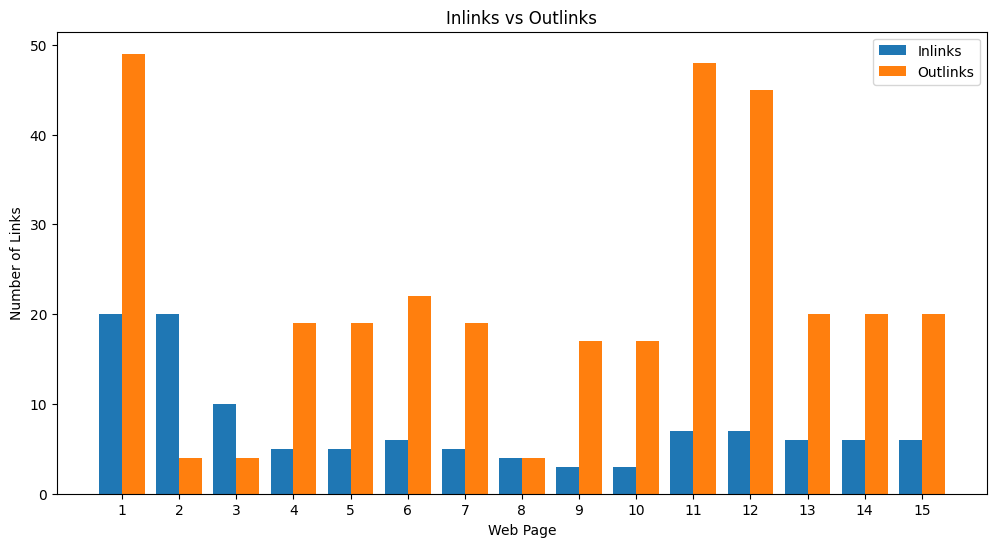

In [57]:
plot_df = graph_stats.head(15)

plt.figure(figsize=(12, 6))

x = range(len(plot_df))

plt.bar(
    [i - 0.2 for i in x],
    plot_df["Inlinks"],
    width=0.4,
    label="Inlinks"
)

plt.bar(
    [i + 0.2 for i in x],
    plot_df["Outlinks"],
    width=0.4,
    label="Outlinks"
)

plt.xticks(x, range(1, len(plot_df) + 1))
plt.xlabel("Web Page")
plt.ylabel("Number of Links")
plt.title("Inlinks vs Outlinks")
plt.legend()
plt.show()

In [58]:
pagerank = nx.pagerank(G)

pagerank_df = pd.DataFrame(
    pagerank.items(),
    columns=["URL", "PageRank"]
)

pagerank_df = pagerank_df.sort_values(
    by="PageRank",
    ascending=False
)

display(pagerank_df.head(15))

,URL,PageRank
0,https://quotes.toscrape.com,0.022811
1,https://quotes.toscrape.com/login,0.022811
47,https://www.goodreads.com/quotes,0.022811
48,https://www.zyte.com,0.022811
38,https://quotes.toscrape.com/tag/inspirational,0.012214
37,https://quotes.toscrape.com/tag/love,0.012214
40,https://quotes.toscrape.com/tag/humor,0.012214
43,https://quotes.toscrape.com/tag/friendship,0.012214
44,https://quotes.toscrape.com/tag/friends,0.012214
39,https://quotes.toscrape.com/tag/life,0.012214


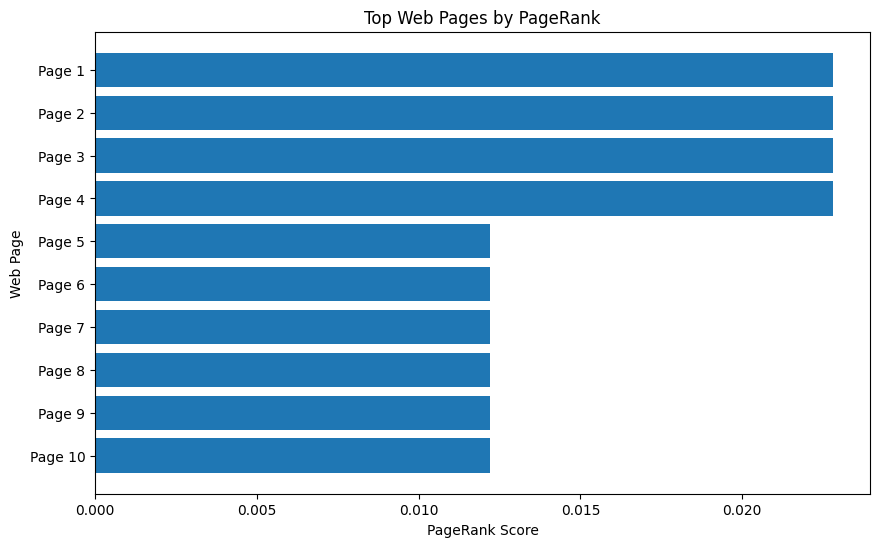

In [59]:
top_pr = pagerank_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    range(len(top_pr)),
    top_pr["PageRank"]
)

plt.yticks(
    range(len(top_pr)),
    [f"Page {i+1}" for i in range(len(top_pr))]
)

plt.xlabel("PageRank Score")
plt.ylabel("Web Page")
plt.title("Top Web Pages by PageRank")
plt.gca().invert_yaxis()

plt.show()

In [60]:
hubs, authorities = nx.hits(G, max_iter=1000)

hits_df = pd.DataFrame({
    "URL": list(G.nodes()),
    "Hub Score": [hubs[n] for n in G.nodes()],
    "Authority Score": [authorities[n] for n in G.nodes()]
})

hits_df = hits_df.sort_values(
    by="Authority Score",
    ascending=False
)

display(hits_df.head(10))

,URL,Hub Score,Authority Score
0,https://quotes.toscrape.com,0.078062,0.036118
1,https://quotes.toscrape.com/login,0.014184,0.036118
47,https://www.goodreads.com/quotes,0.000000,0.036118
48,https://www.zyte.com,0.000000,0.036118
38,https://quotes.toscrape.com/tag/inspirational,0.000000,0.034069
37,https://quotes.toscrape.com/tag/love,0.000000,0.034069
40,https://quotes.toscrape.com/tag/humor,0.000000,0.034069
43,https://quotes.toscrape.com/tag/friendship,0.000000,0.034069
44,https://quotes.toscrape.com/tag/friends,0.000000,0.034069
39,https://quotes.toscrape.com/tag/life,0.000000,0.034069


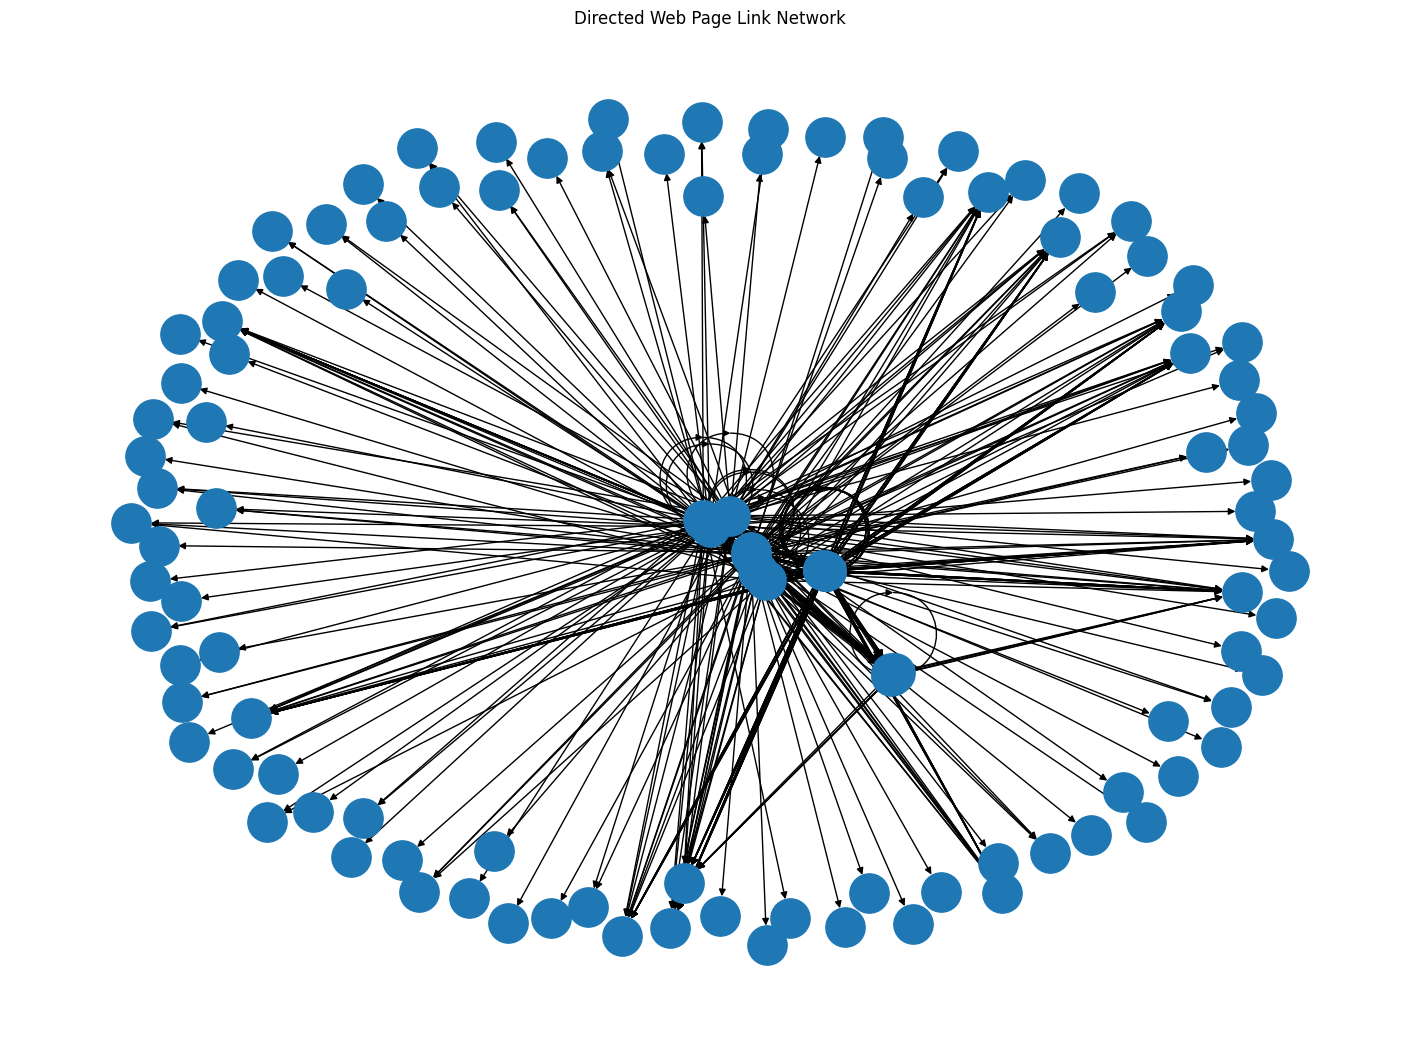

In [61]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=800,
    arrows=True
)

plt.title("Directed Web Page Link Network")
plt.show()

In [62]:
final_results = graph_stats.merge(
    pagerank_df,
    on="URL",
    how="left"
)

final_results = final_results.merge(
    hits_df,
    on="URL",
    how="left"
)

final_results = final_results.sort_values(
    by="PageRank",
    ascending=False
)

display(final_results.head(15))

final_results.to_csv(
    "web_crawler_link_analysis_results.csv",
    index=False
)

print("✅ Results saved successfully!")
print("Top Page by PageRank:")
print(final_results.iloc[0]["URL"])

,URL,Inlinks,Outlinks,PageRank,Hub Score,Authority Score
0,https://quotes.toscrape.com,20,49,0.022811,0.078062,0.036118
1,https://quotes.toscrape.com/login,20,4,0.022811,0.014184,0.036118
47,https://www.goodreads.com/quotes,20,0,0.022811,0.000000,0.036118
48,https://www.zyte.com,20,0,0.022811,0.000000,0.036118
38,https://quotes.toscrape.com/tag/inspirational,16,0,0.012214,0.000000,0.034069
37,https://quotes.toscrape.com/tag/love,16,0,0.012214,0.000000,0.034069
40,https://quotes.toscrape.com/tag/humor,16,0,0.012214,0.000000,0.034069
43,https://quotes.toscrape.com/tag/friendship,16,0,0.012214,0.000000,0.034069
44,https://quotes.toscrape.com/tag/friends,16,0,0.012214,0.000000,0.034069
39,https://quotes.toscrape.com/tag/life,16,0,0.012214,0.000000,0.034069


✅ Results saved successfully!
Top Page by PageRank:
https://quotes.toscrape.com
